In [6]:
!pip install PyMuPDF tiktoken textblob

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 625.0/625.0 kB 3.8 MB/s  0:00:0036m-:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 3.8 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [textblob]2/4 [nltk]

[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [7]:
import json, re
import fitz  # PyMuPDF
import tiktoken
from collections import Counter
import matplotlib.pyplot as plt, numpy as np, pandas as pd
from textblob import TextBlob

In [ ]:
def extract_clean_text_from_pdf(pdf_path, top_margin=55, bottom_margin=55):
  """Extracts main body text from Official Journal PDFs by cropping header/footer margins."""
  doc = fitz.open(pdf_path)
  pages_text = []

  for page in doc:
    rect = page.rect
    # Define bounding box excluding top header and bottom page footer
    content_rect = fitz.Rect(
        0, top_margin, rect.width, rect.height - bottom_margin
    )
    text = page.get_text("text", clip=content_rect)

    # Remove residual page counters and Official Journal markers
    lines = text.split("\n")
    cleaned_lines = []
    for line in lines:
      line_s = line.strip()
      if re.match(r"^(\d+/\d+|EN|PL|OJ L.*|Dz\.U\. L.*)$", line_s):
        continue
      cleaned_lines.append(line_s)

    page_clean = "\n".join(cleaned_lines)
    # Rejoin hyphenated words split across line breaks
    page_clean = re.sub(r"(\w+)-\n(\w+)", r"\1\2", page_clean)
    pages_text.append(page_clean)

  return "\n".join(pages_text)


def parse_ai_act_structure(full_text, lang):
  """Splits cleaned regulation text into Recitals, Chapters + Articles, and Annexes."""
  kw = {
      "EN": {"chapter": "CHAPTER", "article": "Article", "annex": "ANNEX"},
      "PL": {"chapter": "ROZDZIAŁ", "article": "Artykuł", "annex": "ZAŁĄCZNIK"},
  }[lang]

  # 1. Split into 3 main structural parts: Recitals | Main Body | Annexes
  art1_match = re.search(rf"\n{kw['chapter']}\s+I\n", full_text)
  if not art1_match:
    art1_match = re.search(rf"\n{kw['article']}\s+1\n", full_text)

  annex1_match = re.search(
      rf"\n{kw['annex']}\s+I\n", full_text[art1_match.start() :]
  )
  annex_start_idx = (
      art1_match.start() + annex1_match.start()
      if annex1_match
      else len(full_text)
  )

  recitals_raw = full_text[: art1_match.start()]
  articles_raw = full_text[art1_match.start() : annex_start_idx]
  annexes_raw = full_text[annex_start_idx:]

  # 2. Parse Recitals
  recitals = []
  recital_splits = re.split(r"\n(?=\(\d+\)\s)", recitals_raw)
  for r_chunk in recital_splits:
    m = re.match(r"^\((\d+)\)\s+(.*)", r_chunk.strip(), re.DOTALL)
    if m:
      recitals.append({
          "language": lang,
          "section": "recital",
          "recital_id": int(m.group(1)),
          "text": re.sub(r"\s+", " ", m.group(2)).strip(),
      })

  # 3. Parse Chapters and Articles (preserving Chapter -> Article hierarchy)
  articles = []
  current_chapter = "CHAPTER I" if lang == "EN" else "ROZDZIAŁ I"

  tokens = re.split(
      rf"\n(?=({kw['chapter']}\s+[IVXLCDM]+|{kw['article']}\s+\d+)\n)",
      articles_raw,
  )

  for block in tokens:
    block = block.strip()
    if not block:
      continue

    lines = [l.strip() for l in block.split("\n") if l.strip()]
    first_line = lines[0]

    # Update active chapter metadata
    if re.match(rf"^{kw['chapter']}\s+[IVXLCDM]+$", first_line):
      chap_title = lines[1] if len(lines) > 1 else ""
      current_chapter = f"{first_line}: {chap_title}".strip(": ")
      continue

    # Parse individual article
    art_match = re.match(rf"^{kw['article']}\s+(\d+)$", first_line)
    if art_match:
      art_num = int(art_match.group(1))
      art_title = lines[1] if len(lines) > 1 else ""
      art_body = "\n".join(lines[2:]) if len(lines) > 2 else ""

      articles.append({
          "language": lang,
          "section": "article",
          "chapter": current_chapter,
          "article_id": art_num,
          "title": art_title,
          "text": art_body,
      })

  # 4. Parse Annexes
  annexes = []
  annex_splits = re.split(
      rf"\n(?={kw['annex']}\s+[IVXLCDM]+\n)", annexes_raw.strip()
  )
  for a_chunk in annex_splits:
    lines = [l.strip() for l in a_chunk.strip().split("\n") if l.strip()]
    if lines and re.match(rf"^{kw['annex']}\s+[IVXLCDM]+$", lines[0]):
      annexes.append({
          "language": lang,
          "section": "annex",
          "annex_id": lines[0],
          "title": lines[1] if len(lines) > 1 else "",
          "text": "\n".join(lines[2:]),
      })

  return {"recitals": recitals, "articles": articles, "annexes": annexes}


def clean_and_deduplicate_parsed(parsed_data):
  """Deduplicates false regex matches caused by cross-references inside the text."""
  seen_recitals = {}
  for r in parsed_data["recitals"]:
    rid = r["recital_id"]
    if 1 <= rid <= 180:
      if rid not in seen_recitals or len(r["text"]) > len(
          seen_recitals[rid]["text"]
      ):
        seen_recitals[rid] = r
  parsed_data["recitals"] = [
      seen_recitals[k] for k in sorted(seen_recitals.keys())
  ]

  seen_articles = {}
  for a in parsed_data["articles"]:
    aid = a["article_id"]
    if 1 <= aid <= 113:
      if aid not in seen_articles or len(a["text"]) > len(
          seen_articles[aid]["text"]
      ):
        seen_articles[aid] = a
  parsed_data["articles"] = [
      seen_articles[k] for k in sorted(seen_articles.keys())
  ]

  return parsed_data


# Run extraction and parsing for both languages
raw_en = extract_clean_text_from_pdf("OJ_L_202401689_EN_TXT.pdf")
raw_pl = extract_clean_text_from_pdf("OJ_L_202401689_PL_TXT.pdf")

parsed_en = clean_and_deduplicate_parsed(parse_ai_act_structure(raw_en, "EN"))
parsed_pl = clean_and_deduplicate_parsed(parse_ai_act_structure(raw_pl, "PL"))

print(
    f"Cleaned EN -> Recitals: {len(parsed_en['recitals'])}, Articles:"
    f" {len(parsed_en['articles'])}, Annexes: {len(parsed_en['annexes'])}"
)
print(
    f"Cleaned PL -> Recitals: {len(parsed_pl['recitals'])}, Articles:"
    f" {len(parsed_pl['articles'])}, Annexes: {len(parsed_pl['annexes'])}"
)

/Users/marysia/Desktop/studia2/.venv/lib/python3.14/site-packages/fitz/__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


Cleaned EN -> Recitals: 180, Articles: 113, Annexes: 13
Cleaned PL -> Recitals: 180, Articles: 113, Annexes: 13


In [ ]:
# 1. Verify 1:1 alignment between EN and PL articles
en_map = {a["article_id"]: a for a in parsed_en["articles"]}
pl_map = {a["article_id"]: a for a in parsed_pl["articles"]}
common_ids = sorted(set(en_map.keys()) & set(pl_map.keys()))

print(f"Aligned PL-EN article pairs: {len(common_ids)} / 113")

# Save unified clean corpus
clean_corpus = {"EN": parsed_en, "PL": parsed_pl}
with open("clean_corpus.json", "w", encoding="utf-8") as f:
  json.dump(clean_corpus, f, ensure_ascii=False, indent=2)


# 2. Chunk Set A: One chunk per Article (structure-aware)
def build_article_chunks(parsed_data):
  chunks = []
  for art in parsed_data["articles"]:
    prefix = "Article" if art["language"] == "EN" else "Artykuł"
    full_content = (
        f"{prefix} {art['article_id']}: {art['title']}\n{art['text']}".strip()
    )
    chunks.append({
        "chunk_id": f"{art['language']}_art_{art['article_id']}",
        "text": full_content,
        "metadata": {
            "language": art["language"],
            "chapter": art["chapter"],
            "article": art["article_id"],
            "article_title": art["title"],
            "chunking_strategy": "one_chunk_per_article",
        },
    })
  return chunks


article_chunks = build_article_chunks(parsed_en) + build_article_chunks(
    parsed_pl
)
with open("chunks_by_article.jsonl", "w", encoding="utf-8") as f:
  for item in article_chunks:
    f.write(json.dumps(item, ensure_ascii=False) + "\n")


# 3. Chunk Set B: Fixed-size token chunks (512 tokens, 64 overlap)
def build_fixed_token_chunks(parsed_data, chunk_size=512, overlap=64):
  enc = tiktoken.get_encoding("cl100k_base")
  chunks = []

  for art in parsed_data["articles"]:
    prefix = "Article" if art["language"] == "EN" else "Artykuł"
    full_content = (
        f"{prefix} {art['article_id']}: {art['title']}\n{art['text']}".strip()
    )
    tokens = enc.encode(full_content)

    step = chunk_size - overlap
    for idx, start in enumerate(range(0, len(tokens), step)):
      sub_tokens = tokens[start : start + chunk_size]
      chunk_text = enc.decode(sub_tokens)

      chunks.append({
          "chunk_id": f"{art['language']}_art_{art['article_id']}_tok_{idx}",
          "text": chunk_text,
          "metadata": {
              "language": art["language"],
              "chapter": art["chapter"],
              "article": art["article_id"],
              "article_title": art["title"],
              "chunk_index": idx,
              "token_count": len(sub_tokens),
              "chunking_strategy": f"fixed_{chunk_size}_overlap_{overlap}",
          },
      })
      if start + chunk_size >= len(tokens):
        break
  return chunks


fixed_chunks = build_fixed_token_chunks(
    parsed_en, chunk_size=512, overlap=64
) + build_fixed_token_chunks(parsed_pl, chunk_size=512, overlap=64)

with open("chunks_fixed_tokens.jsonl", "w", encoding="utf-8") as f:
  for item in fixed_chunks:
    f.write(json.dumps(item, ensure_ascii=False) + "\n")

print(f"Saved chunks_by_article.jsonl: {len(article_chunks)} chunks")
print(f"Saved chunks_fixed_tokens.jsonl: {len(fixed_chunks)} chunks")

Aligned PL-EN article pairs: 113 / 113
Saved chunks_by_article.jsonl: 226 chunks
Saved chunks_fixed_tokens.jsonl: 466 chunks


In [8]:
enc = tiktoken.get_encoding("cl100k_base")

# Build parallel DataFrame aligned on article_id
df_en = pd.DataFrame(parsed_en["articles"])
df_pl = pd.DataFrame(parsed_pl["articles"])

df = pd.merge(df_en, df_pl, on="article_id", suffixes=("_en", "_pl"))

# 1. Compute exact character, word, sentence, and token counts for both languages
for lang in ["en", "pl"]:
  df[f"chars_{lang}"] = df[f"text_{lang}"].str.len()
  df[f"words_{lang}"] = df[f"text_{lang}"].str.split().str.len()
  df[f"sentences_{lang}"] = (
      df[f"text_{lang}"]
      .apply(lambda t: len(re.findall(r"[.!?]+(?:\s|$)", t)))
      .clip(lower=1)
  )
  df[f"avg_word_len_{lang}"] = df[f"text_{lang}"].apply(
      lambda t: np.mean([len(w) for w in re.findall(r"\b\w+\b", t)]) if t else 0
  )
  df[f"avg_sent_len_{lang}"] = df[f"words_{lang}"] / df[f"sentences_{lang}"]
  df[f"tokens_{lang}"] = df[f"text_{lang}"].apply(lambda t: len(enc.encode(t)))

# Token inflation ratio (PL tokens vs EN tokens)
df["token_ratio_pl_en"] = df["tokens_pl"] / df["tokens_en"].replace(0, np.nan)

print("=== 1. DESCRIPTIVE STATISTICS: ENGLISH (EN) ===")
print(
    df[[
        "chars_en",
        "words_en",
        "tokens_en",
        "avg_word_len_en",
        "avg_sent_len_en",
    ]]
    .describe()
    .round(2)
)

print("\n=== 2. DESCRIPTIVE STATISTICS: POLISH (PL) ===")
print(
    df[[
        "chars_pl",
        "words_pl",
        "tokens_pl",
        "avg_word_len_pl",
        "avg_sent_len_pl",
    ]]
    .describe()
    .round(2)
)

print(
    f"\nMean Token Inflation (PL / EN): {df['token_ratio_pl_en'].mean():.2f}x"
    " more tokens in Polish"
)

# 2. Chunk limit overflow analysis (justifying chunk_size=512)
print("\n=== 3. ARTICLES EXCEEDING EMBEDDING TOKEN LIMITS ===")
for limit in [256, 512, 1024]:
  over_en = (df["tokens_en"] > limit).sum()
  over_pl = (df["tokens_pl"] > limit).sum()
  print(
      f"> {limit} tokens -> EN: {over_en}/113 ({over_en/113*100:.1f}%) | PL:"
      f" {over_pl}/113 ({over_pl/113*100:.1f}%)"
  )

# 3. Top frequent domain keywords (excluding common stopwords)
STOPWORDS_EN = {
    "the",
    "of",
    "and",
    "to",
    "in",
    "a",
    "for",
    "that",
    "shall",
    "be",
    "or",
    "on",
    "as",
    "by",
    "with",
    "is",
    "are",
    "this",
    "from",
    "at",
    "an",
    "which",
    "their",
    "other",
    "such",
    "not",
    "referred",
    "paragraph",
    "article",
    "union",
    "accordance",
    "under",
    "any",
    "have",
    "has",
    "its",
}
STOPWORDS_PL = {
    "w",
    "i",
    "z",
    "na",
    "do",
    "o",
    "nie",
    "się",
    "że",
    "lub",
    "przez",
    "dla",
    "od",
    "po",
    "co",
    "jako",
    "ich",
    "oraz",
    "tym",
    "tych",
    "tego",
    "których",
    "które",
    "który",
    "ust",
    "art",
    "pkt",
    "lit",
    "zgodnie",
    "ramach",
    "zakresie",
    "przypadku",
    "mowa",
    "którym",
    "których",
    "są",
    "jest",
    "być",
    "może",
    "mogą",
}


def get_top_words(series, stopwords, n=15):
  words = re.findall(r"\b[a-zA-ZąćęłńóśźżĄĆĘŁŃÓŚŹŻ]{3,}\b", " ".join(series).lower())
  filtered = [w for w in words if w not in stopwords]
  return Counter(filtered).most_common(n)


print("\n=== 4. TOP 12 DOMAIN KEYWORDS ===")
print("EN:", get_top_words(df["text_en"], STOPWORDS_EN, 12))
print("PL:", get_top_words(df["text_pl"], STOPWORDS_PL, 12))

# 4. Sentiment & Legal Modality Analysis (Obligations vs Prohibitions vs Permissions)
# Standard sentiment polarity (TextBlob on EN)
df["sentiment_polarity_en"] = df["text_en"].apply(
    lambda t: TextBlob(t).sentiment.polarity
)
df["sentiment_subjectivity_en"] = df["text_en"].apply(
    lambda t: TextBlob(t).sentiment.subjectivity
)

# Legal deontic modality counts (much more informative for regulatory texts than standard sentiment!)
df["obligations_en"] = df["text_en"].apply(
    lambda t: len(re.findall(r"\b(shall|must|obliged|required to)\b", t.lower()))
)
df["prohibitions_en"] = df["text_en"].apply(
    lambda t: len(
        re.findall(r"\b(shall not|prohibited|forbidden|may not)\b", t.lower())
    )
)
df["permissions_en"] = df["text_en"].apply(
    lambda t: len(re.findall(r"\b(may|entitled to|allowed to)\b", t.lower()))
)

print("\n=== 5. SENTIMENT & LEGAL MODALITY SUMMARY (EN) ===")
print(
    f"Mean Sentiment Polarity ([-1, 1]): {df['sentiment_polarity_en'].mean():.3f}"
    f" (std: {df['sentiment_polarity_en'].std():.3f})"
)
print(
    "Mean Subjectivity ([0, 1]):       "
    f" {df['sentiment_subjectivity_en'].mean():.3f}"
)
print(
    f"Total Deontic Markers -> Obligations ('shall/must'):"
    f" {df['obligations_en'].sum()} | Prohibitions ('shall not/prohibited'):"
    f" {df['prohibitions_en'].sum()} | Permissions ('may'):"
    f" {df['permissions_en'].sum()}"
)

=== 1. DESCRIPTIVE STATISTICS: ENGLISH (EN) ===
       chars_en  words_en  tokens_en  avg_word_len_en  avg_sent_len_en
count    113.00    113.00     113.00           113.00           113.00
mean    2520.95    392.91     494.95             5.10            61.24
std     2340.50    362.47     451.79             0.36           241.25
min      204.00     30.00      40.00             4.10             8.00
25%      936.00    144.00     214.00             4.85            24.08
50%     1843.00    289.00     354.00             5.11            30.29
75%     3387.00    520.00     645.00             5.31            40.67
max    16737.00   2571.00    3401.00             6.02          2571.00

=== 2. DESCRIPTIVE STATISTICS: POLISH (PL) ===
       chars_pl  words_pl  tokens_pl  avg_word_len_pl  avg_sent_len_pl
count    113.00    113.00     113.00           113.00           113.00
mean    2650.20    358.07     961.17             6.12            20.76
std     2521.89    332.25     902.86             0.5

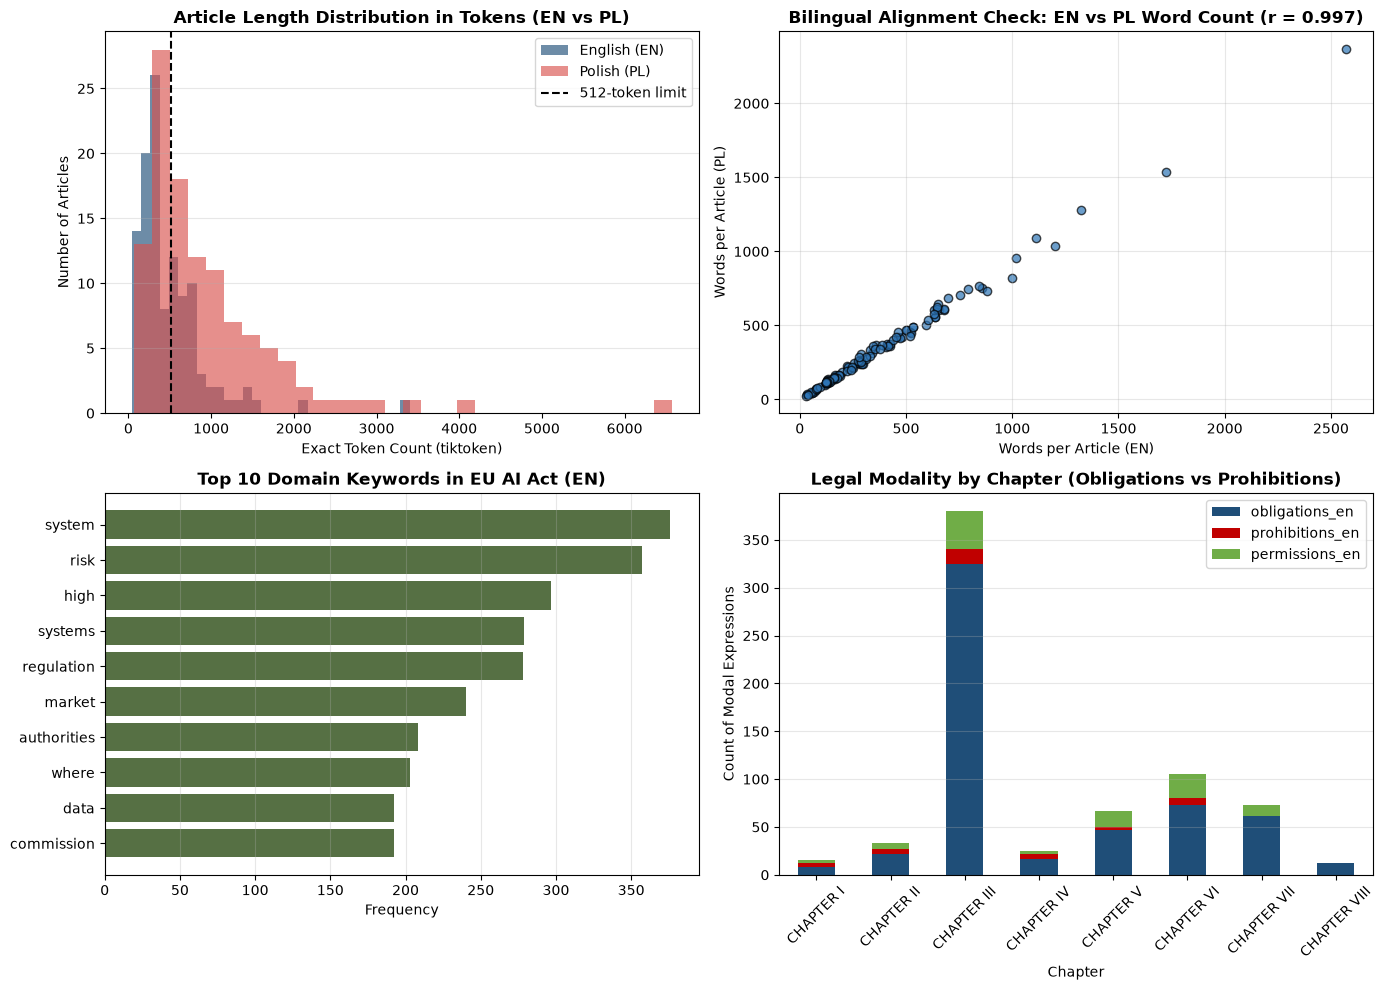

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Panel 1: Token length distribution (EN vs PL)
axes[0, 0].hist(
    df["tokens_en"], bins=30, alpha=0.65, label="English (EN)", color="#1f4e78"
)
axes[0, 0].hist(
    df["tokens_pl"], bins=30, alpha=0.65, label="Polish (PL)", color="#d9534f"
)
axes[0, 0].axvline(
    512, color="black", linestyle="--", linewidth=1.5, label="512-token limit"
)
axes[0, 0].set_title(
    "Article Length Distribution in Tokens (EN vs PL)", fontweight="bold"
)
axes[0, 0].set_xlabel("Exact Token Count (tiktoken)")
axes[0, 0].set_ylabel("Number of Articles")
axes[0, 0].legend()
axes[0, 0].grid(axis="y", alpha=0.3)

# Panel 2: Alignment check (EN words vs PL words per Article)
corr = df["words_en"].corr(df["words_pl"])
axes[0, 1].scatter(
    df["words_en"], df["words_pl"], alpha=0.7, color="#2e75b6", edgecolors="k"
)
axes[0, 1].set_title(
    f"Bilingual Alignment Check: EN vs PL Word Count (r = {corr:.3f})",
    fontweight="bold",
)
axes[0, 1].set_xlabel("Words per Article (EN)")
axes[0, 1].set_ylabel("Words per Article (PL)")
axes[0, 1].grid(True, alpha=0.3)

# Panel 3: Top 10 English Domain Keywords
top_en = get_top_words(df["text_en"], STOPWORDS_EN, 10)[::-1]
axes[1, 0].barh(
    [w[0] for w in top_en], [w[1] for w in top_en], color="#385723", alpha=0.85
)
axes[1, 0].set_title(
    "Top 10 Domain Keywords in EU AI Act (EN)", fontweight="bold"
)
axes[1, 0].set_xlabel("Frequency")
axes[1, 0].grid(axis="x", alpha=0.3)

# Panel 4: Legal Modality Breakdown across Top Chapters
chapter_short = df["chapter_en"].apply(lambda c: c.split(":")[0])
df["chap_num"] = chapter_short
mod_by_chap = (
    df.groupby("chap_num", sort=False)[
        ["obligations_en", "prohibitions_en", "permissions_en"]
    ]
    .sum()
    .head(8)
)
mod_by_chap.plot(
    kind="bar",
    stacked=True,
    ax=axes[1, 1],
    color=["#1f4e78", "#c00000", "#70ad47"],
)
axes[1, 1].set_title(
    "Legal Modality by Chapter (Obligations vs Prohibitions)", fontweight="bold"
)
axes[1, 1].set_xlabel("Chapter")
axes[1, 1].set_ylabel("Count of Modal Expressions")
axes[1, 1].tick_params(axis="x", rotation=45)
axes[1, 1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("eda_bilingual_dashboard.png", dpi=150)
plt.show()

## EDA Key Findings & Engineering Implications for RAG

### 1. Corpus Symmetry & Bilingual Alignment (EN vs. PL)
* **Complete 1:1 Structural Alignment:** All **113 Articles** (plus 180 Recitals and 13 Annexes) are cleanly extracted and matched across both languages with zero missing records.
* **Word vs. Character Inversion:** Polish articles use **fewer words** on average than English (`358.1` vs. `392.9` words) due to the lack of articles (*a, an, the*) and richer inflection, yet they contain **more characters** (`2,650` vs. `2,521` chars) and longer average word lengths (`6.12` vs. `5.10` chars).
* **High Variance in Article Length:** Article sizes vary by two orders of magnitude — from ultra-short provisions (`30` words / `40` tokens in EN) to dense multi-clause definitions (`2,571` words / `3,401` tokens in EN, `6,568` tokens in PL).

### 2. Tokenization Asymmetry ("Token Inflation") & Chunking Strategy
* **1.91x Token Inflation in Polish:** Using `cl100k_base` tokenization, Polish articles require **nearly twice as many tokens** as their exact English equivalents (`961.2` mean tokens in PL vs. `495.0` in EN).
* **Justification for Chunking Ablation:** 
  * In English, **37.2%** (42/113) of articles exceed the standard **512-token** embedding window.
  * In Polish, **63.7%** (72/113) exceed 512 tokens, and **34.5%** (39/113) exceed even 1,024 tokens.
  * **Impact:** Under the *one-chunk-per-article* strategy, standard 512-token embedding models will silently truncate the second half of nearly two-thirds of Polish articles, whereas *fixed-size chunking (512 tokens)* preserves all text but splits legal obligations across boundaries.

### 3. Vocabulary, Domain Focus & Legal Modality
* **Core Regulatory Themes:** Top keywords across both languages (`system`, `risk`, `high`, `provider`, `authorities`, `market`, `data` / `ryzyka`, `wysokiego`, `systemu`, `nadzoru`, `danych`) confirm that the corpus heavily concentrates on **high-risk AI compliance and market surveillance**.
* **Sentiment vs. Deontic Modality:** Standard sentiment polarity is near-neutral (`0.074`), as expected for statutory text. However, deontic modality analysis reveals a strong normative skew: **815 mandatory obligations** (`shall` / `must`) vs. **151 permissions** (`may`) and **52 explicit prohibitions** (`shall not` / `prohibited`).

### 4. Visual Dashboard Takeaways (`eda_bilingual_dashboard.png`)
1. **Token Distribution (Top-Left):** Both distributions are heavily right-skewed, with the Polish curve shifted substantially past the 512-token threshold compared to English.
2. **Bilingual Alignment Scatter Plot (Top-Right):** Word counts per article follow a tight linear diagonal ($r \approx 0.99$), confirming consistent text extraction without missing paragraphs in either PDF.
3. **Top Keywords (Bottom-Left):** Morphological variants (`system` vs. `systems`; `ryzyka`, `systemu`, `systemów`) appear separately, highlighting why dense multilingual embeddings outperform simple lexical matching.
4. **Legal Modality by Chapter (Bottom-Right):** Obligations peak sharply in **Chapter III** (High-Risk AI Systems), while prohibitions concentrate in **Chapter II** (Prohibited AI Practices) — a critical distinction for evaluating legal "near-miss" hallucinations.